In [6]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
path_directory =os.path.join("/Users", "laurageneaulibourne", "Downloads", "S5", "Deep_learning", "project")
path_dataset = os.path.join(path_directory, "archive-4", "diabetes_012_health_indicators_BRFSS2015.csv")

df = pd.read_csv(path_dataset)

# Random split 80% train / 20% test 
df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=df[
        "Diabetes_012"
    ],  # keep the same proportion of 0, 1 et 2 dans train et test
)

# Save the train and test datasets to CSV files
train_path = os.path.join(path_directory, "dataset", "train.csv")
test_path = os.path.join(path_directory, "dataset", "test.csv")

df_train.to_csv(train_path, index=False)
df_test.to_csv(test_path, index=False)


Train : 202944 lignes (80.0%)
Test  : 50736 lignes (20.0%)


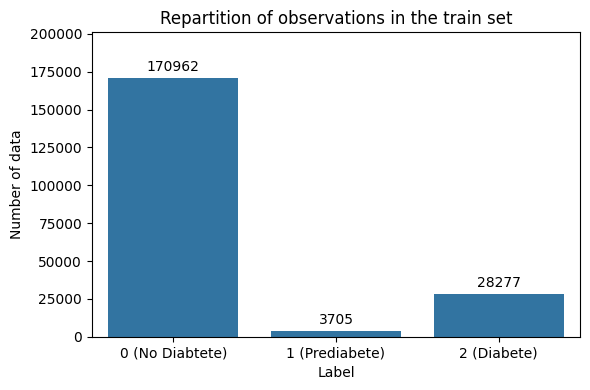

In [11]:
target = "Diabetes_012"

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_train, x=target)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["0 (No Diabtete)", "1 (Prediabete)", "2 (Diabete)"])
ax.set_xlabel("Label")
ax.set_ylabel("Number of data")
ax.set_title("Repartition of observations in the train set")

ax.set_ylim(0, ax.get_ylim()[1] * 1.12)

plt.tight_layout()
plt.show()

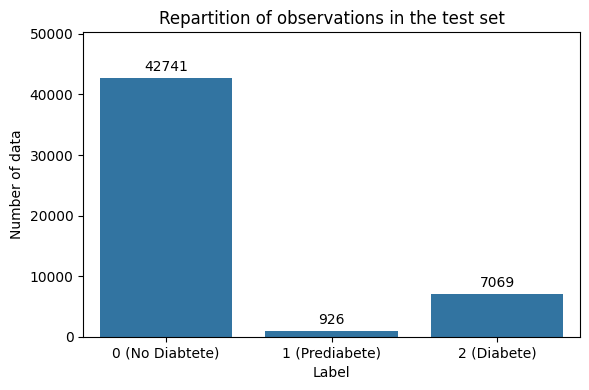

In [ ]:

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_test, x=target)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["0 (No Diabtete)", "1 (Prediabete)", "2 (Diabete)"])
ax.set_xlabel("Label")
ax.set_ylabel("Number of data")
ax.set_title("Repartition of observations in the test set")

ax.set_ylim(0, ax.get_ylim()[1] * 1.12)

plt.tight_layout()
plt.show()

In [17]:
# Rebalance the training dataset to have the same number of samples for the classes 0 and 2. 
df_0 = df_train[df_train[target] == 0]  
df_1 = df_train[df_train[target] == 1] 
df_2 = df_train[df_train[target] == 2]

df_0_sampled = df_0.sample(n=len(df_2), random_state=42)

df_train = (
    pd.concat([df_0_sampled, df_1, df_2])
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

df_train.to_csv(train_path, index=False)


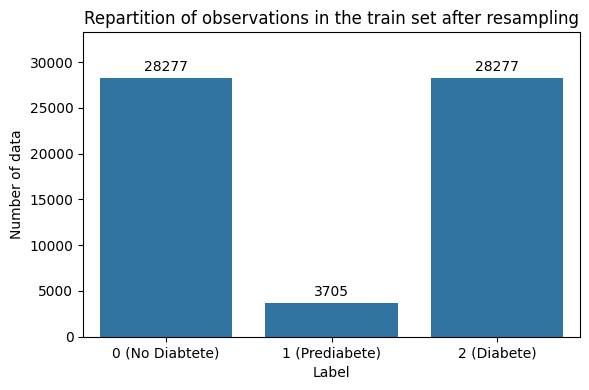

In [18]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_train, x=target)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["0 (No Diabtete)", "1 (Prediabete)", "2 (Diabete)"])
ax.set_xlabel("Label")
ax.set_ylabel("Number of data")
ax.set_title("Repartition of observations in the train set after resampling")

ax.set_ylim(0, ax.get_ylim()[1] * 1.12)

plt.tight_layout()
plt.show()